# BCAS Rate Impact Analysis — 1 CCP

Experiment: `20260601_112636_scenario_1ccp_1btg`

Plots:
1. T1 BCAS death rate vs BCAS rate
2. T1 waiting times at CCP (transport + care) vs BCAS rate
3. Fraction of T2 treated within timeline vs BCAS rate
4. T2 waiting times at CCP (transport + care) vs BCAS rate

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FOLDER_NAME = "20260602_182831_scenario_1ccp_1btg_t2_20min"
df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
levels = sorted(df["bcas_rate"].unique())
print(f"Loaded {len(df)} runs  |  bcas_rate levels: {levels}")

Loaded 200 runs  |  bcas_rate levels: [np.float64(0.03), np.float64(0.07)]


In [2]:
def boxplot_by_bcas(outcome, ylabel, title, ax=None):
    """Boxplot of an outcome column grouped by bcas_rate."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    levels = sorted(df["bcas_rate"].unique())
    data = [df.loc[df["bcas_rate"] == lv, outcome].dropna().values for lv in levels]
    bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d) > 0:
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel("BCAS Rate")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    return ax

## 0. Casualties Generated by Triage and BCAS Rate

C:\Users\User\AppData\Local\Temp\ipykernel_26844\3829578931.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=triage_labels, patch_artist=True, widths=0.5)
C:\Users\User\AppData\Local\Temp\ipykernel_26844\3829578931.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=triage_labels, patch_artist=True, widths=0.5)


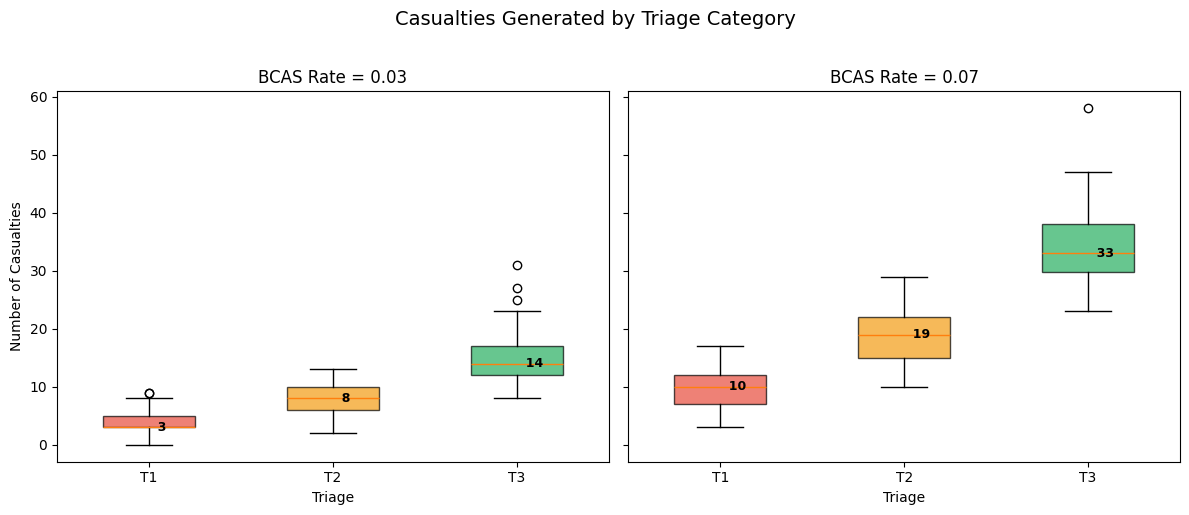

In [3]:
bcas_levels = sorted(df["bcas_rate"].unique())
triage_cols = ["n_patients_T1_BCAS", "n_patients_T2_BCAS", "n_patients_T3_BCAS"]
triage_labels = ["T1", "T2", "T3"]

fig, axes = plt.subplots(1, len(bcas_levels), figsize=(6 * len(bcas_levels), 5), sharey=True)
if len(bcas_levels) == 1:
    axes = [axes]

for ax, rate in zip(axes, bcas_levels):
    sub = df[df["bcas_rate"] == rate]
    data = [sub[col].dropna().values for col in triage_cols]
    bp = ax.boxplot(data, labels=triage_labels, patch_artist=True, widths=0.5)
    colors = ["#e74c3c", "#f39c12", "#27ae60"]
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d) > 0:
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.0f}", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel("Triage")
    ax.set_title(f"BCAS Rate = {rate}")

axes[0].set_ylabel("Number of Casualties")
fig.suptitle("Casualties Generated by Triage Category", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 1. T1 BCAS Death Rate vs BCAS Rate

C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


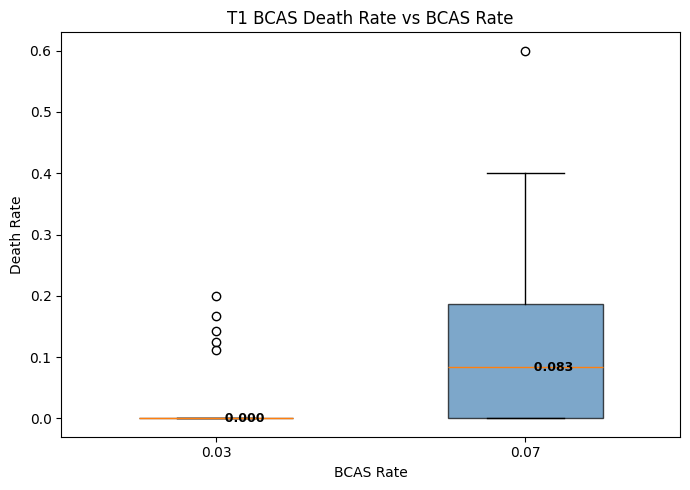

            mean  median    std    min    max
bcas_rate                                    
0.03      0.0075  0.0000 0.0334 0.0000 0.2000
0.07      0.1057  0.0833 0.1237 0.0000 0.6000


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_bcas("death_rate_T1_BCAS", "Death Rate", "T1 BCAS Death Rate vs BCAS Rate", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby("bcas_rate")["death_rate_T1_BCAS"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 2. T1 Waiting Times at CCP vs BCAS Rate

- **Waiting for transport** at CCP (`median_wait_ccp_transport_T1`)
- **Waiting for care** at CCP / R1 (`waiting_care_dcr_t1_bcas_dcr`)

C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


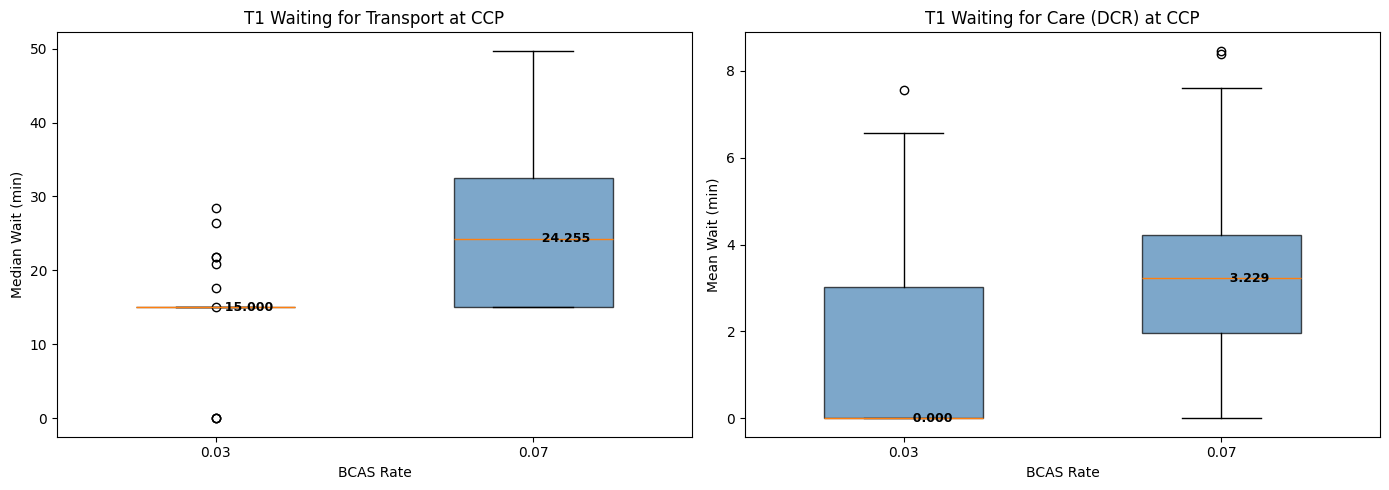


median_wait_ccp_transport_T1:
           mean  median  std
bcas_rate                   
0.03      15.02   15.00 3.37
0.07      24.35   24.25 9.79

waiting_care_dcr_t1_bcas_dcr:
           mean  median  std
bcas_rate                   
0.03       1.38    0.00 2.03
0.07       3.19    3.23 1.84


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

boxplot_by_bcas(
    "median_wait_ccp_transport_T1",
    "Median Wait (min)",
    "T1 Waiting for Transport at CCP",
    ax=axes[0],
)
boxplot_by_bcas(
    "waiting_care_dcr_t1_bcas_dcr",
    "Mean Wait (min)",
    "T1 Waiting for Care (DCR) at CCP",
    ax=axes[1],
)

plt.tight_layout()
plt.show()

for col in ["median_wait_ccp_transport_T1", "waiting_care_dcr_t1_bcas_dcr"]:
    print()
    print(f"{col}:")
    print(df.groupby("bcas_rate")[col].agg(["mean", "median", "std"]).to_string(float_format="%.2f"))

## 3. Fraction of T2 Treated Within Timeline vs BCAS Rate

C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


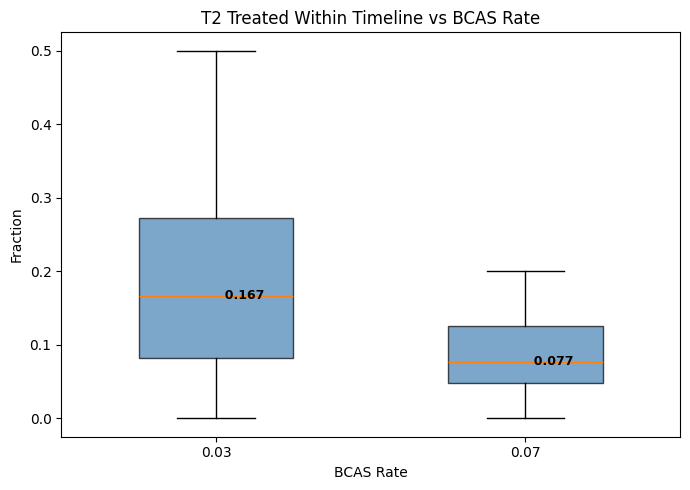

            mean  median    std    min    max
bcas_rate                                    
0.03      0.1738  0.1667 0.1401 0.0000 0.5000
0.07      0.0822  0.0769 0.0526 0.0000 0.2000


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_bcas("frac_t2_within_timeline", "Fraction", "T2 Treated Within Timeline vs BCAS Rate", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby("bcas_rate")["frac_t2_within_timeline"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 4. T2 Waiting Times at CCP vs BCAS Rate

- **Waiting for transport** at CCP (`median_wait_ccp_transport_T2`)
- **Waiting for care** at CCP / R1 (`waiting_care_dcr_t2_bcas_dcr`)

C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
C:\Users\User\AppData\Local\Temp\ipykernel_26844\2887144907.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


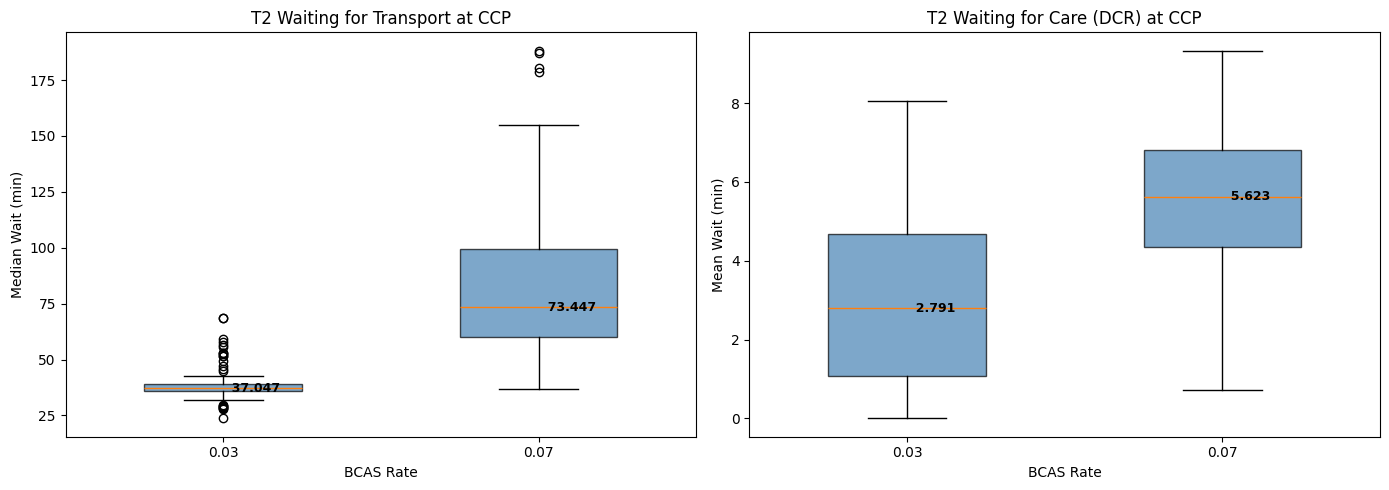


median_wait_ccp_transport_T2:
           mean  median   std
bcas_rate                    
0.03      38.96   37.05  7.68
0.07      83.45   73.45 32.88

waiting_care_dcr_t2_bcas_dcr:
           mean  median  std
bcas_rate                   
0.03       2.99    2.79 2.09
0.07       5.61    5.62 1.72


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

boxplot_by_bcas(
    "median_wait_ccp_transport_T2",
    "Median Wait (min)",
    "T2 Waiting for Transport at CCP",
    ax=axes[0],
)
boxplot_by_bcas(
    "waiting_care_dcr_t2_bcas_dcr",
    "Mean Wait (min)",
    "T2 Waiting for Care (DCR) at CCP",
    ax=axes[1],
)

plt.tight_layout()
plt.show()

for col in ["median_wait_ccp_transport_T2", "waiting_care_dcr_t2_bcas_dcr"]:
    print()
    print(f"{col}:")
    print(df.groupby("bcas_rate")[col].agg(["mean", "median", "std"]).to_string(float_format="%.2f"))